In [1]:
import pandas as pd
import numpy as np
import seaborn as sns


URL = "https://data.seattle.gov/api/views/65db-xm6k/rows.csv?accessType=DOWNLOAD"
# on a déja le fichier en local
local_file = "data/fremont.csv"
from pathlib import Path

if Path(local_file).exists():
    print(f"le fichier {local_file} est déjà là")
else:
    print(f"allons chercher le fichier {local_file}")

    import requests
    req = requests.get(URL)
    print(req.status_code)

    with open(local_file, 'w') as writer:
        writer.write(req.text)


# version naïve
data = pd.read_csv(local_file)
data.shape

data.head()

le fichier data/fremont.csv est déjà là


,Date,Fremont Bridge Total,Fremont Bridge East Sidewalk,Fremont Bridge West Sidewalk
0,08/01/2022 12:00:00 AM,23.0,7.0,16.0
1,08/01/2022 01:00:00 AM,12.0,5.0,7.0
2,08/01/2022 02:00:00 AM,3.0,0.0,3.0
3,08/01/2022 03:00:00 AM,5.0,2.0,3.0
4,08/01/2022 04:00:00 AM,10.0,2.0,8.0


In [2]:
#Doublons
print(data.shape)
data.drop_duplicates(inplace=True)
print(data.shape) 

(175200, 4)
(87600, 4)


In [3]:
#Echauffement DatetimeIndex
sample_dates = pd.to_datetime([
    "2024-01-15 08:00:00",
    "2024-01-20 17:30:00",
    "2024-02-03 12:00:00",])

#1 
print(type(sample_dates))

#sample_dates est de type pandas.DatetimeIndex.

#2

print(sample_dates.date, sample_dates.time, sample_dates.dayofweek)

#Cela renvoie une liste contenant les dates (resp. l'heure, le jour de la semaine sous forme numérique : lundi=0, mardi=1, etc.).

#3
print(sample_dates[sample_dates>pd.to_datetime("2024-01-20 00:00:00")])
#On restreint sample_dates aux éléments ultérieurs au 20 janvier 2024, à minuit.
#N.B. : on peut appliquer pd.to_datetime à un string.

#4
s=sample_dates[pd.to_datetime("2024-01-01 00:00:00")<=sample_dates]
print(s[sample_dates<=pd.to_datetime("2024-01-31 23:59:59")])
#De même qu'en Q3), mais on fait deux restrictions.

<class 'pandas.DatetimeIndex'>
[datetime.date(2024, 1, 15) datetime.date(2024, 1, 20)
 datetime.date(2024, 2, 3)] [datetime.time(8, 0) datetime.time(17, 30) datetime.time(12, 0)] Index([0, 5, 5], dtype='int32')
DatetimeIndex(['2024-01-20 17:30:00', '2024-02-03 12:00:00'], dtype='datetime64[us]', freq=None)
DatetimeIndex(['2024-01-15 08:00:00', '2024-01-20 17:30:00'], dtype='datetime64[us]', freq=None)


In [4]:
#Parser les dates

data.index=pd.to_datetime(data.Date, format="%m/%d/%Y %I:%M:%S %p")
#On a indexé le tableau par les dates (équivalent des clefs primaires en SQL)
del data["Date"]


In [5]:
#Renommage des colonnes 

data.columns=["Total", "West", "East"]
print(data.head())


                     Total  West  East
Date                                  
2022-08-01 00:00:00   23.0   7.0  16.0
2022-08-01 01:00:00   12.0   5.0   7.0
2022-08-01 02:00:00    3.0   0.0   3.0
2022-08-01 03:00:00    5.0   2.0   3.0
2022-08-01 04:00:00   10.0   2.0   8.0


In [ ]:
#Données manquantes et extension types

#1

print(data[data.isna().any(axis=1)].shape)



Nombre de lignes avec valeurs manquantes
(14, 3)


0.9989053092501369


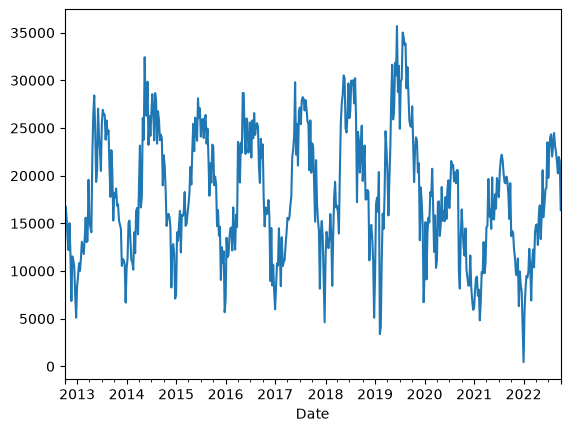

In [7]:
#Changer la fréquence temporelle

#1
newsample=(data['Total'].resample('1W')).sum()
#On "group by" le total des données par semaine, et on somme à chaque fois sur une semaine

newsample.plot()

#2

print((len(data['Total'])/len(newsample))/(7*24)) 
#On voit si le rapport entre les tailles des tableaux avant et après agrégation sont proches de 7*24 : la division du rapport des deux tailles par 7*24 est bien très proche de 1.




In [8]:
#Découpage temporel

data=data[data.index < "2018-01-01"] 

#On peut directement comparer les dates à une chaîne de caractères maintenant que data est indexé par ces dernières.
#Pas besoin de conversion comme avec data.Date

<Axes: xlabel='Date'>

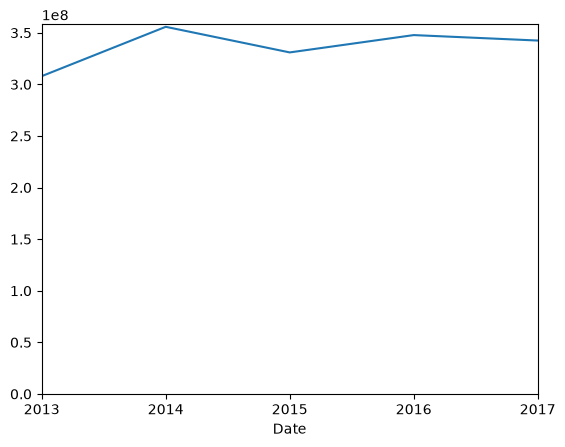

In [9]:
ordonnees=(data['Total'].rolling(365).sum()).resample('1YE').sum() 
#On considère d'abord le tableau constitué de la somme des données des 365 jours précédents, grâce à rolling(365). 
#Ce tableau décrit une évolution quotidienne : on crée donc un nouveau tableau en sommant sur chaque année, grâce à resample. 

ordonnees=ordonnees[ordonnees.index>="2013-01-01 00:00:00"]
#L'année 2012 n'est pas utile à représenter car c'est la première, il n'y a pas de données antérieures pour "lisser". On décide donc de ne pas la représenter.

ordonnees.plot(ylim=(0,None))
#On borne inférieurement l'ensemble d'arrivée, sans préciser de limite supérieure grâce à None.




<Axes: xlabel='time'>

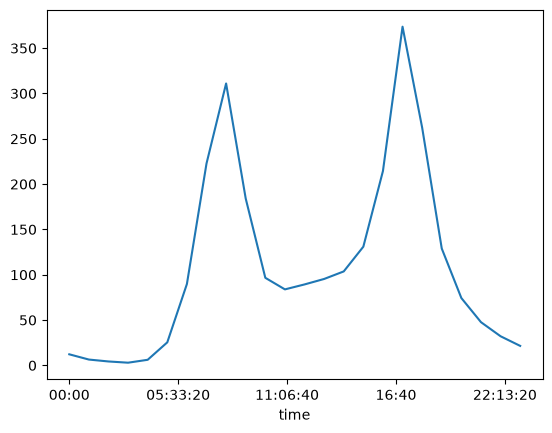

In [ ]:
#Profil journalier moyen

moyenne_quotidienne=data['Total'].groupby(data.index.time).mean()
#On veut l'heure d'affluence en abscisse, on groupby par data.index.time
#[Pour moi : RETENIR : On n'utilise pas resample, qui grouperait en lignes "jour + heure" en gardant la chronologie !]
moyenne_quotidienne.plot()

<Axes: xlabel='time'>

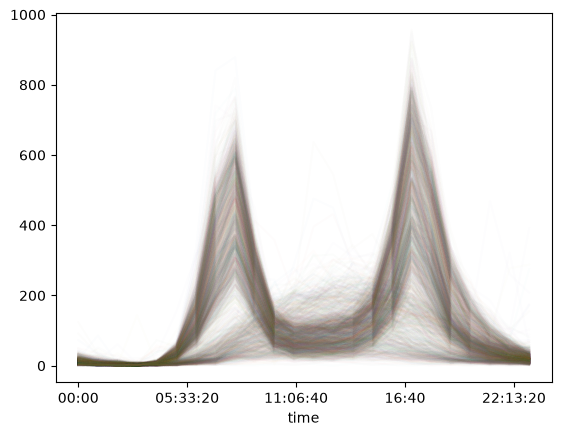

In [11]:
#Une courbe par jour : la pivot_table

pivoted = data.pivot_table('Total',index=data.index.time, columns=data.index.date)
pivoted.plot(legend=False,alpha=0.01)
#On enlève la légende, sinon une liste de plusieurs milliers de jours apparaît, c'est illisible. On règle l'opacité avec un paramètre alpha entre 0 et 1, pour voir les horaires les plus fréquentés.


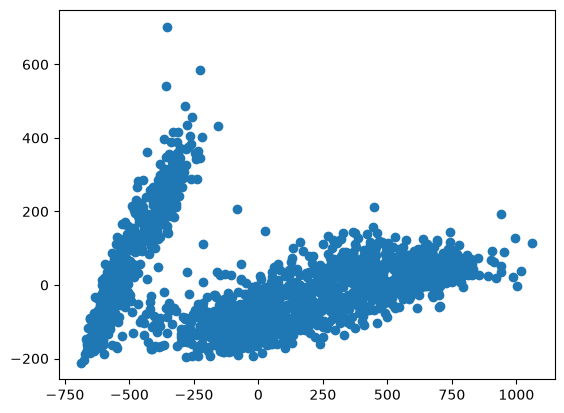

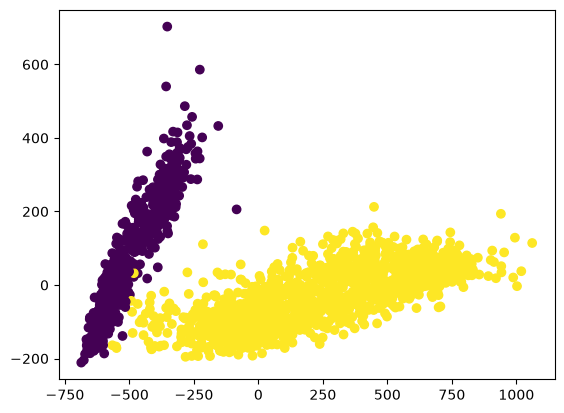

<Axes: xlabel='time'>

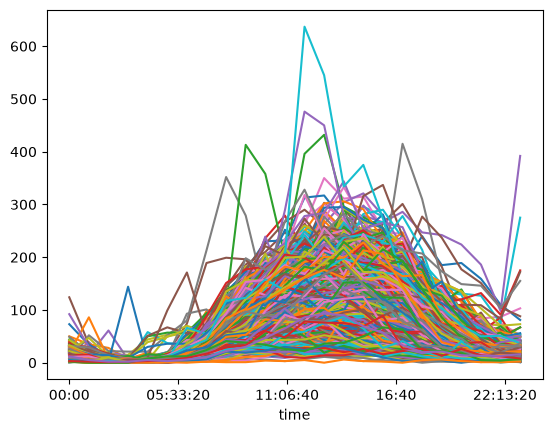

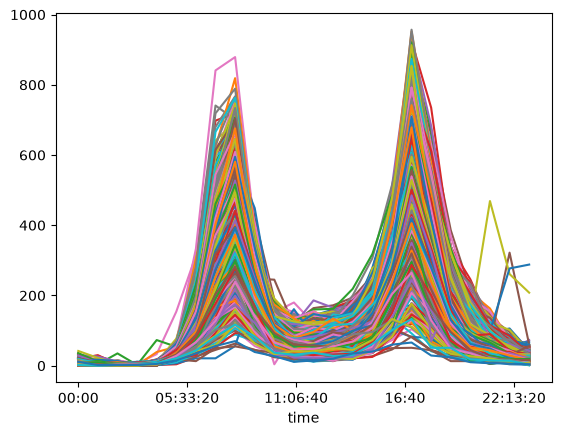

In [12]:
#Classification des jours

from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

pca_input=pivoted.T.fillna(0)

#ACP

nuage_points=PCA(n_components=2).fit_transform(pca_input)
plt.scatter(nuage_points[:,0], nuage_points[:,1])
plt.show()

#GaussianMixture

label=GaussianMixture(n_components=2).fit_predict(pca_input)
plt.scatter(nuage_points[:,0],nuage_points[:,1],c=label)
plt.show()

#Comparaison avec profils journaliers

pivoted_0 = pivoted.loc[:,label==0]
pivoted_1 = pivoted.loc[:, label==1]
#Il faut mettre .loc pour que pandas comprenne qu'on agit sur les colonnes

pivoted_0.plot(legend=False)
pivoted_1.plot(legend=False)

#On observe bien qu'on a tracé à chaque fois des profils journaliers environ de même allure : l'apprentissage a fonctionné.


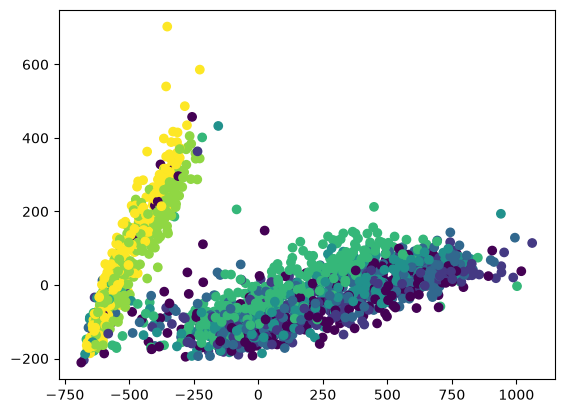

In [ ]:
#Vérifions avec le jour de la semaine

dates=pd.to_datetime(pivoted.columns)
jours=dates.dayofweek
plt.scatter(nuage_points[:,0], nuage_points[:,1], c=jours)

#On reprend le nuage de points précédents, et on voit le numéro de la semaine comme une couleur
#On observe bien que sur des mêmes jours, des "groupes de points types" se profilent


<Axes: xlabel='time'>

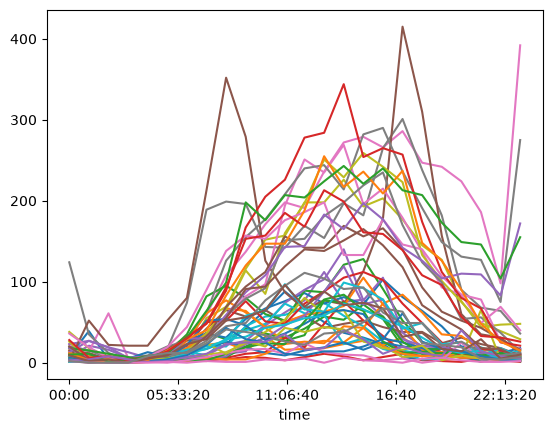

In [ ]:
#Les moutons noirs
new_pivoted=pivoted.loc[:,(jours<5)&(label==0)]

#Je n'ai pas compris la méthode donnée en indice, j'ai donc essayé de m'inspirer de la méthode avec .loc pour pouvoir agir uniquement sur les colonnes de pivoted.
#[Pour moi : RETENIR : .loc permet d'agir sur les lignes ou les colonnes d'une table pivot, et donc d'extraire des sous-ensembles de colonnes de tableaux vérifiant des conditions particulières]

new_pivoted.plot(legend=False)
